In [23]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path

## Load database

In [24]:
# Setup pandas display options
pd.set_option('display.max_columns', None)

BASE_PATH = Path.cwd().parent
DATA_PATH = BASE_PATH / "researchment" / "database" / "indonesia_fintech_paylater.parquet"

# Load the dataset
df = pd.read_parquet(DATA_PATH)
df.head()

,borrower_id,age,gender,province,education_level,employment_status,monthly_income_idr,regional_minimum_wage_umr_idr,num_active_lending_apps,total_loan_outstanding_idr,credit_limit_granted_idr,loan_tenor_months,daily_interest_rate_pct,primary_loan_purpose,debt_to_income_ratio,income_to_umr_ratio,credit_limit_utilization_ratio,monthly_installment_estimate_idr,debt_service_ratio,disposable_income_after_debt_idr,days_past_due,financial_distress_index,twp90_default_status,primary_default_root_cause,cot_financial_psychology_rationale,confidence_score,risk_score,risk_short,is_high_risk,distress_bin
0,ID_DEB_00264B68D1,24,Female,Bali,High School / SMK,Micro-Entrepreneur / UMKM,6420000,2950000,2,8380000,12280000,1,0.35,Daily Living & Emergency Buffer,1.31,2.18,0.6824,9259900.0,1.4424,-2839900.0,67,3.97,Doubtful-DPD61-90,High-Interest-Rate-Compounding,"Debitur 'ID_DEB_00264B68D1' (Female, usia 24 t...",0.961,3,Doubt(61-90),True,"(3.686, 4.588]"
1,ID_DEB_0DE3583B12,28,Female,Bali,Bachelor (S1),Formal Private Employee,8630000,2950000,1,20110000,29060000,6,0.30,Daily Living & Emergency Buffer,2.33,2.93,0.6920,5161567.0,0.5981,3468433.0,11,4.87,Special-Mention-DPD1-30,High-Interest-Rate-Compounding,"Debitur 'ID_DEB_0DE3583B12' (Female, usia 28 t...",0.975,1,SM(1-30),False,"(4.588, 5.49]"
2,ID_DEB_0F661FADC0,20,Female,Bali,High School / SMK,Civil Servant / BUMN,5720000,2950000,4,14960000,23900000,1,0.32,Daily Living & Emergency Buffer,2.62,1.94,0.6259,16396160.0,2.8665,-10676160.0,180,6.07,Default-Macet-TWP90,High-Interest-Rate-Compounding,"Debitur 'ID_DEB_0F661FADC0' (Female, usia 20 t...",0.990,4,Default Rate(>90),True,"(5.49, 6.392]"
3,ID_DEB_10C74D3F21,31,Female,Bali,Bachelor (S1),Civil Servant / BUMN,11780000,2950000,3,7620000,26130000,1,0.26,Daily Living & Emergency Buffer,0.65,3.99,0.2916,8214360.0,0.6973,3565640.0,24,2.35,Special-Mention-DPD1-30,Compulsive-FOMO-Spending,"Debitur 'ID_DEB_10C74D3F21' (Female, usia 31 t...",0.977,1,SM(1-30),False,"(1.882, 2.784]"
4,ID_DEB_12CFCAE01F,22,Male,Bali,Bachelor (S1),Formal Private Employee,6490000,2950000,2,11080000,16420000,9,0.23,Daily Living & Emergency Buffer,1.71,2.20,0.6748,1995631.0,0.3075,4494369.0,0,4.43,Current-Performing,Compulsive-FOMO-Spending,"Debitur 'ID_DEB_12CFCAE01F' (Male, usia 22 tah...",0.980,0,Current,False,"(3.686, 4.588]"


### - **🎯 Task 2: Gen Z Debt-to-Income (DTI) & Financial Distress Index Forecasting**
###    - **Objective:** Forecast continuous `debt_to_income_ratio` and `financial_distress_index` from demographic, educational, and app multiplicity features to establish pre-emptive credit limits and debt caps.
###    - **Recommended ML Models:** Bayesian Ridge Regression, CatBoost Regressor, Deep learning tensorflow.keras (Priority).
###    - **Evaluation Metrics:** `Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), R-Squared (R²)`

## Feature Engineering

In [25]:
# Add datetime features on df
np.random.seed(42)

# Define a realistic time window (e.g. past 2 years up to today)
start_date = pd.to_datetime('2024-11-05')
end_date = pd.to_datetime('2026-11-05')

# Generate 10000 random timestamps between these dates
random_timestamps = np.random.randint(int(start_date.timestamp()), int(end_date.timestamp()), size=len(df))

# Add timestamp features to the DataFrame
df['date'] = pd.to_datetime(random_timestamps, unit='s')
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['is_weekend'] = (df['date'].dt.dayofweek >= 5).astype(int)
df['hour'] = df['date'].dt.strftime('%H:%M:%S')

# Move the date column to the first position
date_col = "date"
columns_move = df.columns.tolist()
columns_move.remove(date_col)

borrower_index = columns_move.index("borrower_id")
columns_move.insert(borrower_index + 1, date_col)

df = df[columns_move]

# Sort the DataFrame by the new 'date' column
df = df.sort_values(by='date').reset_index(drop=True)

In [26]:
# ---- Allowed pre-loan columns -----
ALLOWED_RAW = [
    "age", "gender", "province", "education_level", "employment_status",
    "monthly_income_idr", "regional_minimum_wage_umr_idr",
    "num_active_lending_apps", "credit_limit_granted_idr",
    "loan_tenor_months", "primary_loan_purpose", "daily_interest_rate_pct",
    "income_to_umr_ratio", "date"
]
TARGETS = ["debt_to_income_ratio", "financial_distress_index"]

# Define features
feats = df[ALLOWED_RAW].copy()

# ----- Engineered features -----
feats['year'] = feats['date'].dt.year
feats['month'] = feats['date'].dt.month
feats['day'] = feats['date'].dt.day
feats['is_weekend'] = (feats['date'].dt.dayofweek >= 5).astype(int)
feats['hour'] = feats['date'].dt.hour
feats['credit_limit_to_income'] = feats['credit_limit_granted_idr'] / (feats['monthly_income_idr'] + 1)
feats['credit_limit_to_umr']    = feats['credit_limit_granted_idr'] / (feats['regional_minimum_wage_umr_idr'] + 1)
feats['apps_per_income_m'] = feats['num_active_lending_apps'] / (feats['monthly_income_idr'] / 1e6 + 1)
feats['multi_app_flag'] = (feats['num_active_lending_apps'] >= 3).astype(int)
feats["total_interest_rate"] = feats["daily_interest_rate_pct"] * feats["loan_tenor_months"] * 30
feats["high_edu"] = feats["education_level"].isin(["Bachelor (S1)", "Master (S2)"]).astype(int)
feats["stable_emp"] = feats["employment_status"].isin(["Formal Private Employee","Civil Servant / BUMN"]).astype(int)
feats["income_stability"] = feats["high_edu"] * feats["stable_emp"]

In [27]:
# Grouping province stats
prov_stats = df.groupby('province').agg(
    prov_avg_income=('monthly_income_idr', 'mean'),
    prov_avg_umr=('regional_minimum_wage_umr_idr', 'mean')
).reset_index()

# Merge province stats back to features
feats = feats.merge(prov_stats, on='province', how='left')
feats['income_vs_prov_avg'] = feats['monthly_income_idr'] / (feats['prov_avg_income'] + 1)

In [28]:
# Purpose tier for grouping
PURPOSE_TIER = {"Consumptive":1,"Shopping":1,"Entertainment":1,
                "Education":2,"Medical":2,
                "Business":3,"Working Capital":3,"Productive":3}
feats['purpose_tier'] = feats['primary_loan_purpose'].map(PURPOSE_TIER).fillna(2)

# Build the targets DataFrame
y_dti = df['debt_to_income_ratio'].values.astype("float32")
y_distress = df['financial_distress_index'].values.astype("float32")

## Preprocessing task

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

cat_cols = feats.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = feats.select_dtypes(include=['number']).columns.tolist()

# 1. First split: Separate out a hold-out test set (e.g., 20%)
idx = np.arange(len(feats))
idx_tr_full, idx_te = train_test_split(idx, test_size=0.2, random_state=42)

# 2. Second split: Split the remaining training data into Train and Validation (e.g., 85% train, 15% val)
idx_tr, idx_val = train_test_split(idx_tr_full, test_size=0.15, random_state=42)

# Slice raw features and targets
X_tr_raw, X_val_raw, X_te_raw = feats.iloc[idx_tr], feats.iloc[idx_val], feats.iloc[idx_te]
y_dti_tr, y_dti_val, y_dti_te = y_dti[idx_tr], y_dti[idx_val], y_dti[idx_te]
y_dis_tr, y_dis_val, y_dis_te = y_distress[idx_tr], y_distress[idx_val], y_distress[idx_te]

# 3. Fit ColumnTransformer EXCLUSIVELY on X_tr_raw
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

X_tr = preprocess.fit_transform(X_tr_raw).astype("float32")
X_val = preprocess.transform(X_val_raw).astype("float32")
X_te = preprocess.transform(X_te_raw).astype("float32")

print(f"Training set shape: {X_tr.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Testing set shape: {X_te.shape}")

Training set shape: (6800, 55)
Validation set shape: (1200, 55)
Testing set shape: (2000, 55)


## Build the Multi-Output Neural Network

In [30]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

def build_multi_output_model(input_dim, hidden_units=(128, 64, 32), dropout=0.1, lr=1e-4):
    """
    Build a multi-output neural network model.
    
    Returns:
        model: A compiled Keras model with two layers outputs.
    """
    inputs = layers.Input(shape=(input_dim, ), name="features")

    # Shared trunk
    x = layers.Dense(hidden_units[0], kernel_initializer='he_normal')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(dropout)(x)

    x = layers.Dense(hidden_units[1], kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(dropout)(x)

    # Shared representation
    shared = layers.Dense(hidden_units[2], activation='relu', kernel_initializer='he_normal', name='shared')(x)

    # Head 1: DTI (Debt-to-Income Ratio)
    h1 = layers.Dense(32, activation='relu', kernel_initializer='he_normal')(shared)
    h1 = layers.Dropout(dropout)(h1)
    out_dti = layers.Dense(1, activation='linear', name='dti')(h1)

    # Head 2: Financial Distress Index
    h2 = layers.Dense(32, activation='relu', kernel_initializer='he_normal')(shared)
    h2 = layers.Dropout(dropout)(h2)
    out_dis = layers.Dense(1, activation='linear', name='dis')(h2)

    # Map the output names to the corresponding heads
    model = keras.Model(inputs, {"dti": out_dti, "distress": out_dis})

    # Weighted loss - scale matters for mor DTI
    model.compile(
        optimizer=tf.keras.optimizers.legacy.Adam(learning_rate=lr),
        loss={
            "dti": "mse",
            "distress": "mse"
        },
        loss_weights={
            "dti": 3.0, # Increased from 1.0 to 3.0 to give more importance to DTI prediction
            "distress": 1.0
        },
        metrics={
            "dti": [tf.keras.metrics.R2Score(name="r2")],
            "distress": [tf.keras.metrics.R2Score(name="r2")]
        }
    )
    return model

model = build_multi_output_model(X_tr.shape[1])
model.summary()

Model: "model_2"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 features (InputLayer)       [(None, 55)]                 0         []                            
                                                                                                  
 dense_4 (Dense)             (None, 128)                  7168      ['features[0][0]']            
                                                                                                  
 batch_normalization_4 (Bat  (None, 128)                  512       ['dense_4[0][0]']             
 chNormalization)                                                                                 
                                                                                                  
 activation (Activation)     (None, 128)                  0         ['batch_normalization_4[

## Training with callbacks + tqdm

In [31]:
callbacks_list = [
    callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, mode='min'),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1)
]

# Train the model
history = model.fit(
    X_tr,
    {"dti": y_dti_tr, "distress": y_dis_tr},
    validation_data=(X_val, {"dti": y_dti_val, "distress": y_dis_val}),
    epochs=150,
    batch_size=128,
    callbacks=callbacks_list,
    verbose=1
)


Epoch 1/150
54/54 [==============================] - 3s 26ms/step - loss: 43.8409 - dis_loss: 21.4921 - dti_loss: 7.4496 - dis_r2: -4.1263 - dti_r2: -9.1058 - val_loss: 26.9227 - val_dis_loss: 14.5302 - val_dti_loss: 4.1308 - val_dis_r2: -2.4084 - val_dti_r2: -4.4125 - lr: 1.0000e-04
Epoch 2/150
54/54 [==============================] - 1s 11ms/step - loss: 27.0567 - dis_loss: 13.3821 - dti_loss: 4.5582 - dis_r2: -2.1919 - dti_r2: -5.1835 - val_loss: 17.6069 - val_dis_loss: 9.8997 - val_dti_loss: 2.5691 - val_dis_r2: -1.3222 - val_dti_r2: -2.3662 - lr: 1.0000e-04
Epoch 3/150
54/54 [==============================] - 1s 13ms/step - loss: 18.7184 - dis_loss: 8.5526 - dti_loss: 3.3886 - dis_r2: -1.0400 - dti_r2: -3.5969 - val_loss: 11.9680 - val_dis_loss: 6.3600 - val_dti_loss: 1.8693 - val_dis_r2: -0.4919 - val_dti_r2: -1.4493 - lr: 1.0000e-04
Epoch 4/150
54/54 [==============================] - 1s 12ms/step - loss: 14.8430 - dis_loss: 6.2482 - dti_loss: 2.8649 - dis_r2: -0.4903 - dti_r2: 

In [32]:
history_df = pd.DataFrame(history.history)
history_df

,loss,dis_loss,dti_loss,dis_r2,dti_r2,val_loss,val_dis_loss,val_dti_loss,val_dis_r2,val_dti_r2,lr
0,43.840862,21.492075,7.449592,-4.126312,-9.105818,26.922680,14.530218,4.130820,-2.408428,-4.412503,0.000100
1,27.056711,13.382127,4.558190,-2.191917,-5.183451,17.606869,9.899658,2.569070,-1.322214,-2.366184,0.000100
2,18.718374,8.552558,3.388605,-1.039965,-3.596858,11.967976,6.360027,1.869316,-0.491904,-1.449315,0.000100
3,14.842997,6.248185,2.864937,-0.490324,-2.886463,8.988984,4.558262,1.476908,-0.069255,-0.935152,0.000100
4,12.652578,5.156726,2.498617,-0.229990,-2.389529,7.469556,3.772735,1.232273,0.115010,-0.614615,0.000100
...,...,...,...,...,...,...,...,...,...,...,...
132,2.660672,1.522386,0.379429,0.636879,0.485282,1.520839,0.924264,0.198858,0.783190,0.739441,0.000003
133,2.685952,1.544170,0.380594,0.631684,0.483701,1.518129,0.922429,0.198567,0.783621,0.739823,0.000003
134,2.693712,1.558047,0.378555,0.628373,0.486466,1.520413,0.924320,0.198698,0.783177,0.739652,0.000003
135,2.697189,1.560319,0.378957,0.627831,0.485921,1.510670,0.918431,0.197413,0.784559,0.741335,0.000003


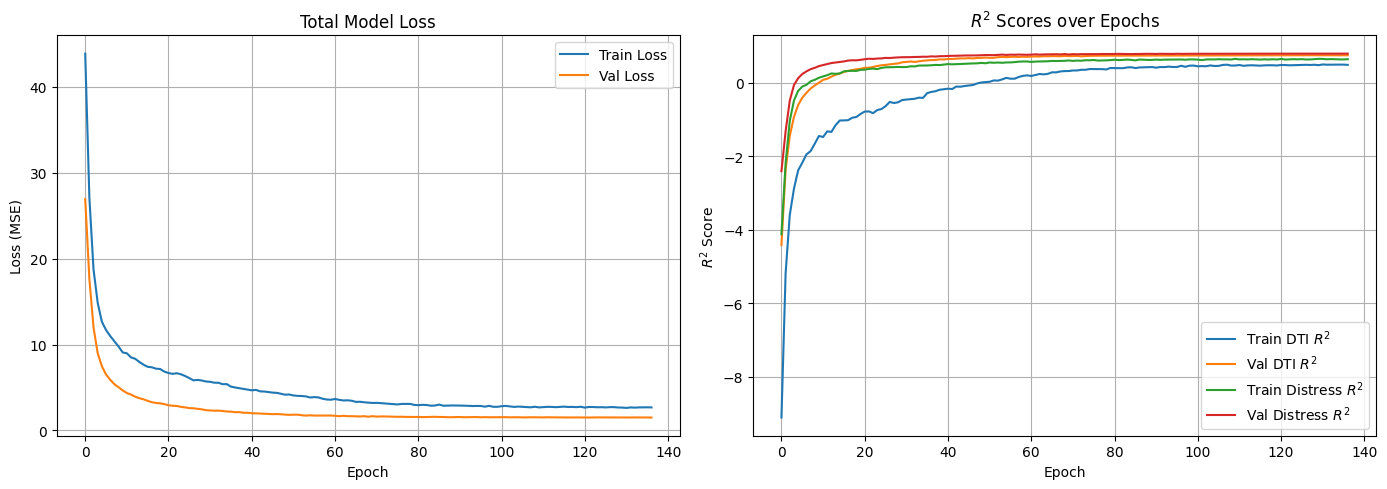

In [33]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Total Model Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (MSE)')
axes[0].legend()
axes[0].grid(True)

# R2 Score plot for DTI and Distress
axes[1].plot(history.history['dti_r2'], label='Train DTI $R^2$')
axes[1].plot(history.history['val_dti_r2'], label='Val DTI $R^2$')
axes[1].plot(history.history['dis_r2'], label='Train Distress $R^2$')
axes[1].plot(history.history['val_dis_r2'], label='Val Distress $R^2$')
axes[1].set_title('$R^2$ Scores over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('$R^2$ Score')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()